<a href="https://colab.research.google.com/github/ralph-Jung/AI-Class/blob/main/6%EC%A3%BC%EC%B0%A8/10_12_abalone_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [9]:
df=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/abalone.csv")

In [11]:
# 1. 입력 / 정답 나누기
X = df.drop(columns=["id", "Sex"]).values.astype("float32")   # 입력 8개 (숫자)

# 정답 Sex를 원-핫 인코딩 (열 순서: F, I, M)
Y_df = pd.get_dummies(df["Sex"])
labels = Y_df.columns.tolist()
Y = Y_df.values.astype("float32")
print("클래스 순서:", labels, "| Y 모양:", Y.shape)

클래스 순서: ['F', 'I', 'M'] | Y 모양: (4177, 3)


In [13]:
# 2. 학습 / 테스트 분할 (Sex 비율 유지)
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=df["Sex"])

In [14]:
# 3. 정규화 (변수마다 범위가 달라서 필요)
#    기준(평균, 표준편차)은 학습 데이터로만 정해야 테스트 정보가 새지 않음
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [18]:
# 4. 모델 구성
#    다중 분류 + 단일 레이블 → 출력층 softmax, 클래스가 3개라 노드 3개
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax"),
])


model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,755 (10.76 KB)

 Trainable params: 2,755 (10.76 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# 5. 학습
# EarlyStopping 으로 val _loss 를 계속 지켜보다가 지금까지 가장 낮았던 값보다 10 에포크 연속 더 낮아지지 않으면 학습을 멈추고
# 가장 좋았던 시점의 가중치로 되돌린다
# 지금 보다 10번때 에포크에서 val_loss 가 0.8917 로 나오고 그 아래 10개가 모두 이것보다 컸기 때문에 멈추고
# 10번째 에포크 일 때의 가중치로 되돌리고 멈춘다
early = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    epochs=200, batch_size=32,
    validation_split=0.2, callbacks=[early], verbose=1)

Epoch 1/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5966 - loss: 0.7950 - val_accuracy: 0.5366 - val_loss: 0.9048
Epoch 2/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5977 - loss: 0.7922 - val_accuracy: 0.5052 - val_loss: 0.9209
Epoch 3/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6055 - loss: 0.7975 - val_accuracy: 0.5321 - val_loss: 0.9037
Epoch 4/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6074 - loss: 0.7903 - val_accuracy: 0.5381 - val_loss: 0.8942
Epoch 5/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6033 - loss: 0.7909 - val_accuracy: 0.5456 - val_loss: 0.9013
Epoch 6/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6048 - loss: 0.7907 - val_accuracy: 0.5277 - val_loss: 0.9124
Epoch 7/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6055 - loss: 0.7883 - val_accuracy: 0.5381 - val_loss: 0.9123
Epoch 8/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6033 - loss: 0.7871 - val_accuracy: 0.5291 - v

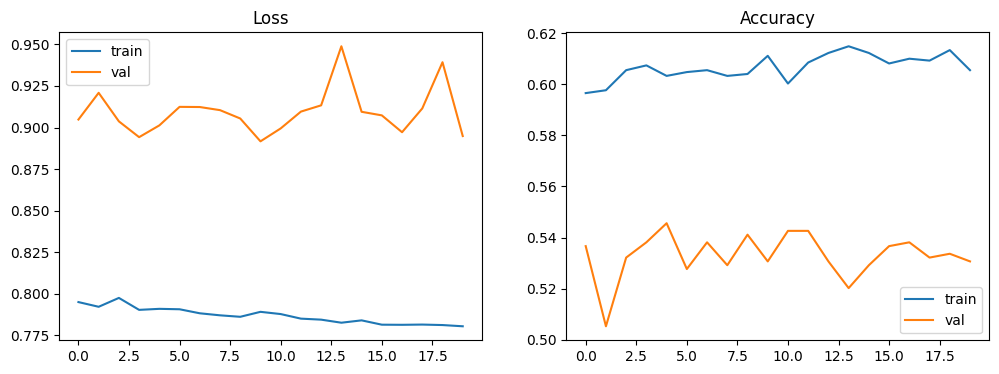

In [24]:
# 6. 학습 곡선 (과적합 여부 확인)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="val")
axes[0].set_title("Loss"); axes[0].legend()
axes[1].plot(history.history["accuracy"], label="train")
axes[1].plot(history.history["val_accuracy"], label="val")
axes[1].set_title("Accuracy"); axes[1].legend()
plt.show()

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Accuracy: 0.5610047846889952
              precision    recall  f1-score   support

           F       0.45      0.33      0.38       261
           I       0.75      0.74      0.74       269
           M       0.49      0.60      0.54       306

    accuracy                           0.56       836
   macro avg       0.56      0.56      0.55       836
weighted avg       0.56      0.56      0.56       836



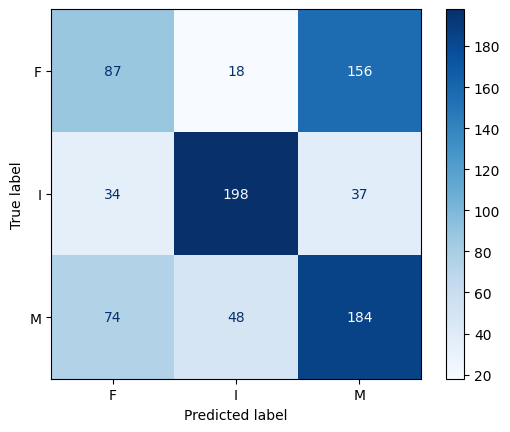

In [23]:
# 7. 평가: 확률 → 클래스 번호, 원-핫 정답 → 클래스 번호
# 지금 보면 정확도가 56% 로 낮다 . 그 중에서도 F 를 M 로 잘못 판단하는 경우가 156 번 이나 된다
# 이걸 보면 해당 데이터 들로 성별 차이를 구분할 수는 없다는 걸 보여준다
y_pred = np.argmax(model.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)
print("Accuracy:", accuracy_score(y_true, y_pred))
print(classification_report(y_true, y_pred, target_names=labels))

ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=labels).plot(cmap="Blues")
plt.show()